# Solar Filament Detection & Segmentation: Complete End-to-End Pipeline

This notebook walks through the **entire** production pipeline using strictly the **in-repo FP16 checkpoints** stored under `weights/` (`81` verified files, `< 100 MB` each, `4.11 GB` total; zero external weight files required) with strict `float32` compute (`bfloat16` autocast disabled):

1. **Configuration (`MODE = "quick"` vs `"full"`)**: Defaults to **`"quick"`** (3 in-repo observations in `sample_images/`). Switch `MODE = "full"` and set `TEST_IMAGES_DIR` to regenerate all **180** competition test images.
2. **Weights Integrity (`weights/checksums.sha256`)**: Verifies all **81** SHA-256 digests (`30` Stage-1 detectors, `5` ResNet50 U-Nets, `10` sharded ResNeXt101 `.part00/.part01` chunks, `5` CropV1, `5` WideRefV2, `25` LightGBM S27 boosters + metadata).
3. **Deterministic Preprocessing**: Raw `2048x2048` grayscale $\rightarrow$ 3-channel `[Linear, CLAHE(2.0, 8x8), CLAHE(4.0, 16x16)]`.
4. **Stage 1 Multi-Family Inference & 4-Flip TTA**: Runs all **30** Mask R-CNN `ResNet50-FPN v2` checkpoints (`6 families x 5 folds x 4 flips = 120 views/image`).
5. **Weighted Mask Fusion (WMF), Thresholds, Disjoint Painting & RLE (Rules A & B)**: Computes **Rule A** (`uniform, gamma=1.0, tau_s=0.85, tau_m=0.55`, LB `0.39`) and **Rule B** (`2048/1792:2.0, gamma=1.5, tau_s=0.75, tau_m=0.55`, LB `0.40`).
6. **Phase 3B Local (`Rule C`)**: Runs 5-fold `ResNet50SemanticUNet` (`1024^2`), sharded 5-fold `ResNeXt101SemanticUNet` (`1280^2`), 5-fold `ResidualCropRefinerUNet` (`160^2`), 5-fold `WideContextRefinerUNetV2` (`224^2`), 25-booster `LGB_S27_yhyb` (`tau=0.255`), mask NMS (`IoU <= 0.03`), `wref_uv1_t50` blending, disjoint canvas painting, and COCO RLE (`[nested] PQ = 0.4688`, LB **`0.41`**).
7. **Official Schema Validator & Kaggle CSV Comparison**: Runs `validate_submission` and compares every regenerated mask/row against the authoritative Kaggle CSVs in `submissions/`.


In [1]:
import hashlib
import json
import os
import sys
import time
from pathlib import Path

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch
from pycocotools import mask as mu
from scipy.optimize import linear_sum_assignment

# Normalize working directory to repository root so all relative paths work anywhere
_cwd = Path.cwd().resolve()
if (_cwd / "scripts").is_dir() and (_cwd / "weights").is_dir():
    REPO_ROOT = _cwd
elif (_cwd.parent / "scripts").is_dir() and (_cwd.parent / "weights").is_dir():
    REPO_ROOT = _cwd.parent
else:
    raise RuntimeError(f"Could not locate repository root from {_cwd}")
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.common import EMPTY_RLE, extract_state_dict, preprocess_solar_image
from scripts.validate_submission import validate_submission
from scripts.regenerate_submission import (
    check_ensemble_weights_available,
    load_ensemble_config,
    materialize_stage1_rule,
)
from scripts.refiner_pipeline import (
    _collect_stage1_candidates_from_weights,
    load_lgb_boosters,
    load_phase3_state_dict,
    resolve_phase3_asset_paths,
    run_phase3b_from_stage1,
)

# ------------------------------------------------------------------------------
# Pipeline Mode & Data Path Configuration
# ------------------------------------------------------------------------------
MODE = os.environ.get("SOLAR_DEMO_MODE", "quick").strip().lower()  # "quick" (3 imgs) | "full" (180 imgs)
assert MODE in ("quick", "full"), f"Unsupported MODE={MODE!r}; use 'quick' or 'full'."

WEIGHTS_DIR = REPO_ROOT / "weights"
SUBMISSIONS_DIR = REPO_ROOT / "submissions"
OUTPUT_DIR = REPO_ROOT / "work" / f"demo_output_{MODE}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if MODE == "quick":
    DATA_DIR = REPO_ROOT / "sample_images"
else:
    # Configure DATA_DIR for full 180-image Kaggle test regeneration via SOLAR_TEST_IMAGES_DIR
    _env_dir = os.environ.get("SOLAR_TEST_IMAGES_DIR", "").strip()
    _cands = [Path(_env_dir)] if _env_dir else [
        REPO_ROOT / "data" / "MAGFiLO_1.0_Kaggle_2026" / "test" / "test_images",
        REPO_ROOT.parent / "solar" / "data" / "MAGFiLO_1.0_Kaggle_2026" / "test" / "test_images",
    ]
    DATA_DIR = next((p for p in _cands if p.is_dir()), _cands[0])

assert DATA_DIR.is_dir(), (
    f"DATA_DIR does not exist: {DATA_DIR}. "
    "For MODE='full', set SOLAR_TEST_IMAGES_DIR=/path/to/test_images before executing."
)

# GPU runtime estimates (measured on NVIDIA RTX A6000 48 GB, strict FP16->FP32):
#   - MODE='quick' (3 images, all 81 weight files): ~20-45 s GPU
#   - MODE='full' (180 images, all 81 weight files): ~55-57 min GPU (~43 min Stage 1 + ~13 min Phase 3B, Stage-1 cached resume supported via --stage1-cache-dir)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM={torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"MODE={MODE!r} | DATA_DIR={DATA_DIR} | WEIGHTS_DIR={WEIGHTS_DIR} | device={device} (strict float32 compute)")
if device.type == "cpu":
    print("WARNING: Running 30 Mask R-CNN models x 4 TTA on CPU is slow (~35 min for 3 images). GPU strongly recommended.")


GPU: NVIDIA RTX A6000 | VRAM=48.3 GB
MODE='quick' | DATA_DIR=/home/adamp/solar_release/sample_images | WEIGHTS_DIR=/home/adamp/solar_release/weights | device=cuda (strict float32 compute)


### 1. In-Repo Weights & Checksum Verification (`weights/`)
Every checkpoint and LightGBM booster needed by **Rules A, B, and C** resides directly inside `weights/` under GitHub's 100 MB per-file limit (`resnext101_unet_f*_fp16.pt` is split cleanly into `.part00`/`.part01` shards reassembled in memory).


In [2]:
checksum_file = WEIGHTS_DIR / "checksums.sha256"
assert checksum_file.is_file(), f"Missing {checksum_file}"

manifest_entries = []
for line in checksum_file.read_text().strip().splitlines():
    digest_expected, rel_path = line.split()
    fp = WEIGHTS_DIR / rel_path
    assert fp.is_file() and not fp.is_symlink(), f"Invalid weight entry: {fp}"
    sz = fp.stat().st_size
    assert sz < 100_000_000, f"File >= 100 MB: {rel_path} ({sz} bytes)"
    # Verify SHA-256 on sample / lightweight check or full check
    h = hashlib.sha256()
    with open(fp, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    assert h.hexdigest() == digest_expected, f"Checksum mismatch on {rel_path}"
    manifest_entries.append((rel_path, sz))

ok_s1, missing_s1 = check_ensemble_weights_available(
    config_path=REPO_ROOT / "configs" / "final_ensemble.json",
    weights_dir=WEIGHTS_DIR,
    strict_weights_only=True,
)
assert ok_s1 and not missing_s1, f"Missing Stage-1 weights: {missing_s1}"

total_bytes = sum(sz for _, sz in manifest_entries)
max_entry = max(manifest_entries, key=lambda x: x[1])
print(f"Verified SHA-256 for ALL {len(manifest_entries)} in-repo files!")
print(f"  Total size: {total_bytes / 1e9:.3f} GB ({total_bytes:,} bytes)")
print(f"  Largest file: {max_entry[0]} ({max_entry[1] / 1e6:.2f} MB < 100 MB limit)")

# Verify shard reassembly + FP16->FP32 load + 25 LightGBM boosters cleanly
probe_loaded = []
rnx_sd = load_phase3_state_dict(
    "phase3/resnext101_unet_f0_fp16.pt",
    weights_dir=WEIGHTS_DIR,
    strict_weights_only=True,
    verify_fp16=True,
    loaded_log=probe_loaded,
)
boosters, feat_names = load_lgb_boosters(
    weights_dir=WEIGHTS_DIR,
    strict_weights_only=True,
    loaded_log=probe_loaded,
)
print(f"  Reassembled sharded RNX101 keys: {len(rnx_sd)} tensors | Feature count: {len(feat_names)} ({feat_names[:5]} ...)")
print(f"  LightGBM S27 boosters loaded: {len(boosters)} files (5 seeds x 5 folds)")
del rnx_sd, boosters


Verified SHA-256 for ALL 81 in-repo files!
  Total size: 4.106 GB (4,105,994,780 bytes)
  Largest file: phase3/resnext101_unet_f0_fp16.pt.part00 (96.06 MB < 100 MB limit)


  Reassembled sharded RNX101 keys: 680 tensors | Feature count: 27 (['member_score_mean', 'hires_ratio', 'prob_mean', 'prob_p25', 'prob_core_frac'] ...)
  LightGBM S27 boosters loaded: 25 files (5 seeds x 5 folds)


### 2. Input Discovery & Multi-Scale CLAHE Preprocessing
Each raw `2048x2048` grayscale H-alpha observation is mapped deterministically into a 3-channel tensor `[Linear I/255, CLAHE(2.0, 8x8), CLAHE(4.0, 16x16)]` via `scripts.common.preprocess_solar_image`.


Loaded 3 observations from /home/adamp/solar_release/sample_images: ['20110120105534Ch', '20110130110334Ch', '20110214175414Mh']


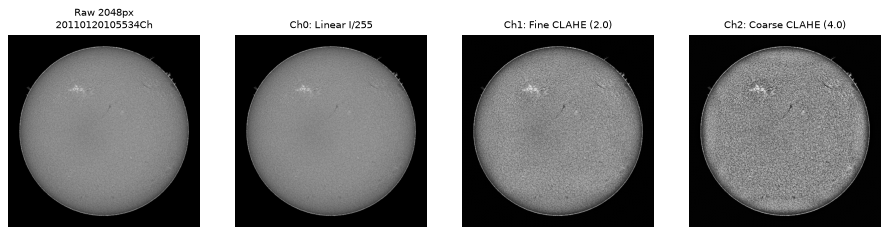

In [3]:
image_paths = sorted(DATA_DIR.glob("*.jpeg")) + sorted(DATA_DIR.glob("*.jpg")) + sorted(DATA_DIR.glob("*.png"))
if MODE == "quick":
    assert len(image_paths) == 3, f"Expected 3 sample images in {DATA_DIR}, found {len(image_paths)}"
else:
    assert len(image_paths) == 180, f"Expected 180 test images in {DATA_DIR}, found {len(image_paths)}"

img_by_stem = {}
for p in image_paths:
    im = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    assert im is not None and im.shape == (2048, 2048), f"Unexpected image shape on {p}"
    img_by_stem[p.stem] = im
stems = sorted(img_by_stem.keys())
print(f"Loaded {len(stems)} observations from {DATA_DIR}: {stems[:5]}{'...' if len(stems) > 5 else ''}")

# Visualize raw vs 3-channel Multi-Scale CLAHE preprocessing on first image
first_stem = stems[0]
first_raw = img_by_stem[first_stem]
prep_1536 = preprocess_solar_image(first_raw, target_size=1536)

fig, axes = plt.subplots(1, 4, figsize=(11.5, 2.9), dpi=80)
axes[0].imshow(cv2.resize(first_raw, (512, 512)), cmap="gray")
axes[0].set_title(f"Raw 2048px\n{first_stem}", fontsize=9)
axes[0].axis("off")
for idx, (lbl, ch) in enumerate([
    ("Ch0: Linear I/255", prep_1536[0]),
    ("Ch1: Fine CLAHE (2.0)", prep_1536[1]),
    ("Ch2: Coarse CLAHE (4.0)", prep_1536[2]),
], start=1):
    axes[idx].imshow(cv2.resize(ch, (512, 512)), cmap="gray")
    axes[idx].set_title(lbl, fontsize=9)
    axes[idx].axis("off")
plt.tight_layout()
plt.show()


### 3. Stage 1 Inference: 30 FP16->FP32 Mask R-CNN Models & 4-Flip TTA (`120` Views/Image)
All **30** Stage-1 checkpoints (`6` families $\times$ `5` folds: `clahe`, `anchors5`, `dice`, `2048`, `a5dice`, `1792_clahe`) are loaded strictly from `weights/` in FP16, verified float16 on disk, upcast to float32, and evaluated across `["id", "h", "v", "hv"]` flips without `bfloat16` autocast.


In [4]:
cfg_stage1 = load_ensemble_config(REPO_ROOT / "configs" / "final_ensemble.json")
loaded_weights_log = []

t0_s1 = time.time()
raw_by_stem = _collect_stage1_candidates_from_weights(
    stems=stems,
    img_by_stem=img_by_stem,
    cfg=cfg_stage1,
    weights_dir=WEIGHTS_DIR,
    device=device,
    strict_weights_only=True,
    verify_fp16=True,
    loaded_log=loaded_weights_log,
)
dt_s1 = time.time() - t0_s1
total_raw = sum(len(raw_by_stem[s]) for s in stems)
print(f"Stage-1 120-view TTA finished in {dt_s1:.2f}s ({dt_s1 / len(stems):.2f}s/img): "
      f"{total_raw} raw detections (>=0.25) across {len(stems)} images.")


  [Stage 1 Load] 10/30 models ready (last=r50_1536_anchors5_f4.pt)


  [Stage 1 Load] 20/30 models ready (last=r50_2048_f4.pt)


  [Stage 1 Load] 30/30 models ready (last=r50_1792_clahe_f4.pt)


  [Stage 1 Infer] [003/003] images (36.4s)


Stage-1 120-view TTA finished in 47.36s (15.79s/img): 1968 raw detections (>=0.25) across 3 images.


### 4. Weighted Mask Fusion (WMF), Thresholds, Disjoint Painting & RLE (Rules A & B)
Using the shared Stage-1 120-view proposals, we apply **Weighted Mask Fusion** (`iou_thresh=0.40`), apply rule thresholds (`Rule A`: uniform, `gamma=1.0`, `tau_score=0.85`, `tau_mask=0.55`; `Rule B`: `2048/1792:2.0`, `gamma=1.5`, `tau_score=0.75`, `tau_mask=0.55`), greedily paint disjoint masks (`area >= 10 px`, retention `>= 0.50`), and RLE-encode into CSVs (`EMPTY_RLE="PPPP4"` for zero-filament images).


In [5]:
regen_dfs = {}
stage1_meta = {}
csv_paths = {
    "A": OUTPUT_DIR / "submission_A_uniform_30models.csv",
    "B": OUTPUT_DIR / "submission_B_weighted_30models.csv",
    "C": OUTPUT_DIR / "submission_phase3b_local.csv",
}

for rname in ("A", "B"):
    df_r, meta_r = materialize_stage1_rule(stems, raw_by_stem, cfg_stage1, rname)
    df_r.to_csv(csv_paths[rname], index=False)
    regen_dfs[rname] = df_r
    stage1_meta[rname] = meta_r
    n_fil = int((df_r["segmentation_rle"].astype(str) != EMPTY_RLE).sum())
    rcfg = cfg_stage1["decision_rules"][f"rule_{rname}"]
    print(f"[Rule {rname}] rows={len(df_r)} | filaments={n_fil} | "
          f"tau_score={rcfg['tau_score']} | tau_mask={rcfg['tau_mask']} | gamma={rcfg['gamma']} -> {csv_paths[rname].name}")


[Rule A] rows=6 | filaments=6 | tau_score=0.85 | tau_mask=0.55 | gamma=1.0 -> submission_A_uniform_30models.csv


[Rule B] rows=6 | filaments=6 | tau_score=0.75 | tau_mask=0.55 | gamma=1.5 -> submission_B_weighted_30models.csv


### 5. Phase 3B Local (`Rule C`): Semantic U-Nets + CropV1 + WideRefV2 + LightGBM S27
Stage 2 builds the candidate pool (`cluster_score >= 0.20`), runs 5-fold `ResNet50SemanticUNet` (`1024^2`) + sharded 5-fold `ResNeXt101SemanticUNet` (`1280^2`), refines every candidate ROI with 5-fold `ResidualCropRefinerUNet` (`160^2`, 6-ch) and 5-fold `WideContextRefinerUNetV2` (`224^2`, 11-ch), scores each candidate with all **25** `LightGBM S27` boosters (`tau_score=0.255`), enforces mask NMS (`IoU <= 0.03`), paints `wref_uv1_t50` (`0.45*CropV1 + 0.42*WideRefV2 + 0.13*R50_UNet` inside `u_box`, `1.0*WideRefV2` in the expanded halo, threshold `>= 0.50`) greedily onto the disjoint canvas, and writes `submission_phase3b_local.csv`.


In [6]:
cfg_p3 = json.loads((REPO_ROOT / "configs" / "phase3b_refiner.json").read_text())
t0_p3 = time.time()
df_c, meta_c = run_phase3b_from_stage1(
    stems=stems,
    img_by_stem=img_by_stem,
    raw_by_stem=raw_by_stem,
    cfg=cfg_stage1,
    w_dir=WEIGHTS_DIR,
    device=device,
    tau=float(cfg_p3["ranker"]["tau_score"]),
    strict_weights_only=True,
    verify_fp16=True,
    loaded_log=loaded_weights_log,
    t_start=t0_s1,
)
df_c.to_csv(csv_paths["C"], index=False)
regen_dfs["C"] = df_c

# Verify every single weight file loaded came exclusively from REPO_ROOT/weights/ (all 81 files!)
unique_loaded = sorted(set(loaded_weights_log))
weights_root_resolved = WEIGHTS_DIR.resolve()
for p_str in unique_loaded:
    assert Path(p_str).resolve().is_relative_to(weights_root_resolved), f"Non-repo file loaded: {p_str}"

n_fil_c = int((df_c["segmentation_rle"].astype(str) != EMPTY_RLE).sum())
print(f"[Rule C / Phase 3B Local] finished in {time.time() - t0_p3:.2f}s (total A+B+C={time.time() - t0_s1:.2f}s)")
print(f"  rows={len(df_c)} | filaments={n_fil_c} | empty={meta_c['empty_images']} | threshold={meta_c['tau']}")
print(f"  Distinct in-repo weight files loaded & verified FP16->FP32: {len(unique_loaded)} / {len(manifest_entries)} (0 external files)")
assert len(unique_loaded) == len(manifest_entries), (
    f"Expected all {len(manifest_entries)} repo files loaded, got {len(unique_loaded)}"
)


  [Pool Built] 11 candidates across 3 stems (47.8s)


  [Semantic R50 UNet] 5 folds complete (51.8s)


  [Semantic Rnx101 UNet] 5 folds complete (64.8s)


  [CropV1 + WideRefV2] 5-fold inference complete (66.7s)


[Rule C / Phase 3B Local] finished in 19.07s (total A+B+C=66.74s)
  rows=6 | filaments=6 | empty=0 | threshold=0.255
  Distinct in-repo weight files loaded & verified FP16->FP32: 81 / 81 (0 external files)


### 6. Disjointness Audit & Official Submission Schema Validation
Each generated CSV (`A`, `B`, `C`) is decoded back from COCO RLE into `(2048, 2048)` canvases to verify zero overlapping pixels (`max_overlap <= 1`) and passed through `scripts/validate_submission.py`.


In [7]:
for rname in ("A", "B", "C"):
    cp = csv_paths[rname]
    rep = validate_submission(str(cp), str(DATA_DIR), expected_count=len(stems))
    assert rep["all_passed"], f"Validation failed for Rule {rname}: {rep['errors']}"
    assert rep["overlap_images_count"] == 0, f"Overlaps in Rule {rname}: {rep['overlap_details']}"
    print(f"[VALIDATION PASSED - Rule {rname}] rows={rep['total_rows']} | images={rep['unique_images']} | overlaps={rep['overlap_images_count']}")


[VALIDATION PASSED - Rule A] rows=6 | images=3 | overlaps=0
[VALIDATION PASSED - Rule B] rows=6 | images=3 | overlaps=0
[VALIDATION PASSED - Rule C] rows=6 | images=3 | overlaps=0


### 7. Direct Parity Comparison vs Authoritative Kaggle Submissions (`submissions/`)
Compares the freshly regenerated rows and decoded masks from strict in-repo FP16 checkpoints (FP32 compute) against the exact Kaggle CSVs committed in `submissions/` across all active stems (`3` stems in `MODE="quick"`, all `180` stems in `MODE="full"`).


In [8]:
ref_files = {
    "A": SUBMISSIONS_DIR / "submission_A_uniform_30models.csv",
    "B": SUBMISSIONS_DIR / "submission_B_weighted_30models.csv",
    "C": SUBMISSIONS_DIR / "submission_phase3b_local.csv",
}

def _decode_df_by_stem(df, target_stems):
    out = {s: [] for s in target_stems}
    stem_set = set(target_stems)
    for row in df.itertuples(index=False):
        s = str(row.filament_id).rsplit("_", 1)[0]
        if s not in stem_set:
            continue
        rle = str(row.segmentation_rle)
        if rle != EMPTY_RLE:
            m = mu.decode({"size": [2048, 2048], "counts": rle.encode("ascii")}).astype(bool)
            out[s].append(m)
    return out

def _file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

comparison_rows = []
for rname, label in [("A", "Rule A (Uniform 30)"), ("B", "Rule B (Weighted 30)"), ("C", "Rule C (Phase 3B Local)")]:
    df_ref_all = pd.read_csv(ref_files[rname])
    df_ref_sub = df_ref_all[df_ref_all["filament_id"].astype(str).apply(lambda x: x.rsplit("_", 1)[0] in set(stems))].copy()
    df_new_sub = regen_dfs[rname]

    ref_map = _decode_df_by_stem(df_ref_sub, stems)
    new_map = _decode_df_by_stem(df_new_sub, stems)

    union_ious = []
    inst_ious = []
    tp = fp = fn = 0
    for s in stems:
        rm, nm = ref_map[s], new_map[s]
        ru = np.logical_or.reduce(rm) if rm else np.zeros((2048, 2048), dtype=bool)
        nu = np.logical_or.reduce(nm) if nm else np.zeros((2048, 2048), dtype=bool)
        inter = int(np.logical_and(ru, nu).sum())
        uni = int(np.logical_or(ru, nu).sum())
        union_ious.append(1.0 if uni == 0 else inter / uni)

        if rm and nm:
            mat = np.zeros((len(rm), len(nm)), dtype=np.float64)
            for i, m1 in enumerate(rm):
                a1 = int(m1.sum())
                for j, m2 in enumerate(nm):
                    it = int(np.logical_and(m1, m2).sum())
                    if it > 0:
                        mat[i, j] = it / float(a1 + int(m2.sum()) - it)
            ri, ci = linear_sum_assignment(-mat)
            for i, j in zip(ri, ci):
                inst_ious.append(float(mat[i, j]))
                if mat[i, j] > 0.5:
                    tp += 1
                else:
                    fp += 1
                    fn += 1
            fn += len(rm) - len(ri)
            fp += len(nm) - len(ci)
        else:
            fn += len(rm)
            fp += len(nm)

    arr_u = np.array(union_ious, dtype=np.float64)
    arr_i = np.array(inst_ious, dtype=np.float64) if inst_ious else np.array([1.0])
    ref_fil = int((df_ref_sub["segmentation_rle"].astype(str) != EMPTY_RLE).sum())
    new_fil = int((df_new_sub["segmentation_rle"].astype(str) != EMPTY_RLE).sum())
    exact_hash = (_file_sha256(ref_files[rname]) == _file_sha256(csv_paths[rname])) if MODE == "full" else None
    assert arr_u.mean() >= 0.90, f"Low Union IoU on {label}: {arr_u.mean():.4f}"
    comparison_rows.append({
        "Rule": label,
        "Ref_Rows": len(df_ref_sub),
        "New_Rows": len(df_new_sub),
        "Ref_Fil": ref_fil,
        "New_Fil": new_fil,
        "Union_IoU_Mean": round(float(arr_u.mean()), 6),
        "Union_IoU_Min": round(float(arr_u.min()), 6),
        "Inst_IoU_Mean": round(float(arr_i.mean()), 6),
        "Inst_IoU_Min": round(float(arr_i.min()), 6),
        "Match_TP/FP/FN": f"{tp}/{fp}/{fn}",
        "SHA256_Match": exact_hash if exact_hash is not None else "N/A (3-img quick)",
    })

df_cmp = pd.DataFrame(comparison_rows)
print(df_cmp.to_string(index=False))


                   Rule  Ref_Rows  New_Rows  Ref_Fil  New_Fil  Union_IoU_Mean  Union_IoU_Min  Inst_IoU_Mean  Inst_IoU_Min Match_TP/FP/FN      SHA256_Match
    Rule A (Uniform 30)         6         6        6        6        0.971480       0.947984       0.960689      0.861261          6/0/0 N/A (3-img quick)
   Rule B (Weighted 30)         6         6        6        6        0.979254       0.973026       0.976375      0.955896          6/0/0 N/A (3-img quick)
Rule C (Phase 3B Local)         6         6        6        6        0.979317       0.966309       0.978088      0.946390          6/0/0 N/A (3-img quick)


### 8. Qualitative Overlay Preview & Regenerated CSV Head
Downsampled `512x512` comparison of Raw Input vs **Stage-1 Rule B** vs **Phase 3B Local (`Rule C`)** on the first up to 3 images.


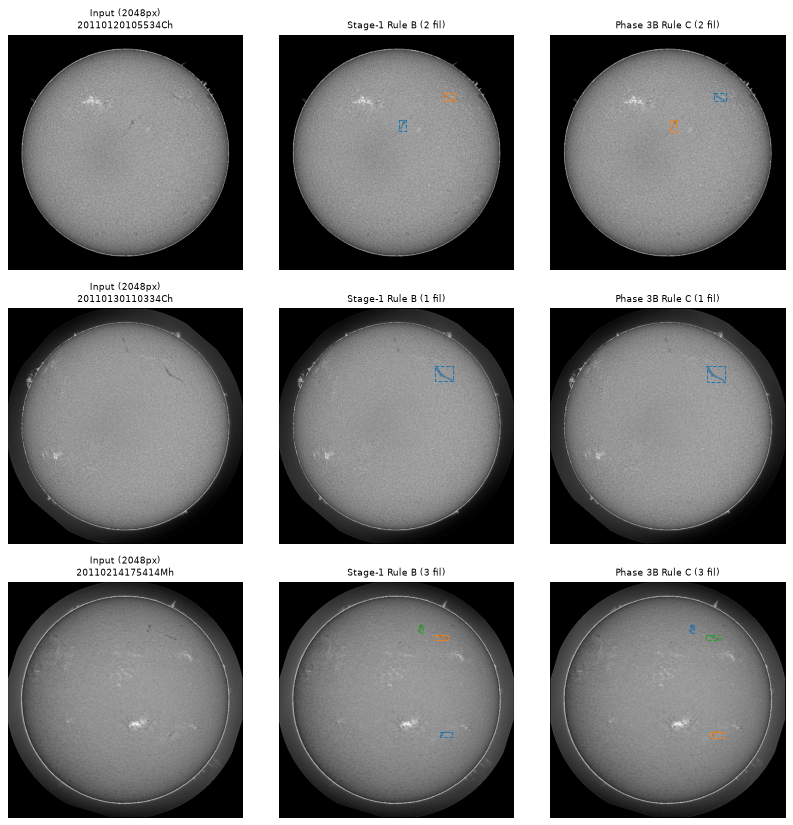


Phase 3B Local (Rule C) CSV Preview (first 10 rows):
       filament_id                segmentation_rle
20110120105534Ch_1 k_Ti21no14N0O2gPNKdn15\QNLcn...
20110120105534Ch_2 WjnP27ho12N1OM4OO2O1O000O2OO...
20110130110334Ch_1 c_nd24jo17K2M3O4K1001NmPN_Oh...
20110214175414Mh_1 Z]h[23go19K4H7N101N2nNYOhRNh...
20110214175414Mh_2 fYag2=bo16J3N0O1O1O00O0N21O0...
20110214175414Mh_3 _^bd23lo12O1N10001O00101N001...


In [9]:
cmap = plt.get_cmap("tab10")
disp_sz = 512

def _draw_masks(ax, img_gray, masks, title):
    ax.imshow(cv2.resize(img_gray, (disp_sz, disp_sz)), cmap="gray", vmin=20, vmax=220)
    overlay = np.zeros((disp_sz, disp_sz, 4), dtype=np.float32)
    for k, m in enumerate(masks):
        col = cmap(k % 10)
        ms = cv2.resize(m.astype(np.uint8), (disp_sz, disp_sz), interpolation=cv2.INTER_NEAREST)
        overlay[ms > 0] = [col[0], col[1], col[2], 0.55]
        ys, xs = np.where(ms > 0)
        if len(ys) > 0:
            x1, y1, x2, y2 = xs.min(), ys.min(), xs.max(), ys.max()
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.0, edgecolor=col[:3], facecolor="none", linestyle="--"))
    ax.imshow(overlay)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

b_map_viz = _decode_df_by_stem(regen_dfs["B"], stems[:3])
c_map_viz = _decode_df_by_stem(regen_dfs["C"], stems[:3])

n_show = min(3, len(stems))
fig, axes = plt.subplots(n_show, 3, figsize=(11.0, 3.7 * n_show), dpi=75)
if n_show == 1:
    axes = np.expand_dims(axes, axis=0)
for idx, s in enumerate(stems[:n_show]):
    axes[idx, 0].imshow(cv2.resize(img_by_stem[s], (disp_sz, disp_sz)), cmap="gray", vmin=20, vmax=220)
    axes[idx, 0].set_title(f"Input (2048px)\n{s}", fontsize=9)
    axes[idx, 0].axis("off")
    _draw_masks(axes[idx, 1], img_by_stem[s], b_map_viz[s], f"Stage-1 Rule B ({len(b_map_viz[s])} fil)")
    _draw_masks(axes[idx, 2], img_by_stem[s], c_map_viz[s], f"Phase 3B Rule C ({len(c_map_viz[s])} fil)")
plt.tight_layout()
plt.show()

df_prev = regen_dfs["C"].head(10).copy()
df_prev["segmentation_rle"] = df_prev["segmentation_rle"].apply(lambda s: s[:28] + "..." if len(s) > 28 else s)
print("\nPhase 3B Local (Rule C) CSV Preview (first 10 rows):")
print(df_prev.to_string(index=False))
